    Step 1: Data Understanding & Preprocessing
    •	Load and explore the dataset.
    •	Check for missing values and handle them.
    •	Convert categorical variables (Fuel_Type, Mileage, Airbags) into numerical format.


In [1]:
import pandas as pd
import numpy as np
path=r"https://raw.githubusercontent.com/rushidhende06-pixel/Datasets/refs/heads/main/car_price_prediction.csv"
df=pd.read_csv(path)
df.head()


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [2]:
df.shape

(19237, 18)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

In [4]:
df.isna().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [5]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage                 str
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [55]:
# Remove 'km' and convert Mileage to numeric (kitihi vela run kela tari chalel)
df["Mileage"] = (
    df["Mileage"]
    .astype(str)
    .str.replace(" km", "", regex=False)
    .astype(float)
)

print(df["Mileage"].head())
print("\nMileage Data Type:", df["Mileage"].dtype)

0    186005.0
1    192000.0
2    200000.0
3    168966.0
4     91901.0
Name: Mileage, dtype: float64

Mileage Data Type: float64


In [7]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder
le = LabelEncoder()

# Convert Fuel type into numerical format
df["Fuel type"] = le.fit_transform(df["Fuel type"].astype(str))

# Display the result
print(df["Fuel type"].head())

# Display category mapping
print("\nFuel Type Mapping:")
for category, number in zip(le.classes_, le.transform(le.classes_)):
    print(category, ":", number)

0    2
1    5
2    5
3    2
4    5
Name: Fuel type, dtype: int64

Fuel Type Mapping:
CNG : 0
Diesel : 1
Hybrid : 2
Hydrogen : 3
LPG : 4
Petrol : 5
Plug-in Hybrid : 6


In [40]:
print(df["Fuel type"].value_counts())

Fuel type
5    10150
1     4036
2     3578
4      892
0      494
6       86
3        1
Name: count, dtype: int64


In [41]:
# Convert Airbags to numeric format
df["Airbags"] = pd.to_numeric(df["Airbags"], errors="coerce")

# Display the result
print(df["Airbags"].head())

# Check data type
print("\nAirbags Data Type:", df["Airbags"].dtype)

0    12
1     8
2     2
3     0
4     4
Name: Airbags, dtype: int64

Airbags Data Type: int64


In [42]:
# Levy: "-" mhanje missing -> NaN, mag number
df["Levy"] = pd.to_numeric(df["Levy"].replace("-", np.nan))

# Engine volume: "2.0 Turbo" -> 2.0 ani Turbo flag
df["Engine"] = df["Engine volume"].str.extract(r"(\d+\.?\d*)").astype(float)
df["Turbo"] = df["Engine volume"].str.contains("Turbo").astype(int)

# Age (gadi kiti junee ahe) - Prod. year peksha upyogi
df["Age"] = 2020 - df["Prod. year"]

df[["Levy", "Engine", "Turbo", "Age", "Mileage", "Airbags"]].head()

,Levy,Engine,Turbo,Age,Mileage,Airbags
0,1399.0,3.5,0,10,186005.0,12
1,1018.0,3.0,0,9,192000.0,8
2,NaN,1.3,0,14,200000.0,2
3,862.0,2.5,0,9,168966.0,0
4,446.0,1.3,0,6,91901.0,4


In [43]:
df = df.drop_duplicates()

In [45]:
upper_price = df["Price"].quantile(0.995)
df = df[
    (df["Price"] >= 500) & (df["Price"] <= upper_price) &
    (df["Mileage"] > 0) & (df["Mileage"] < 1_000_000)
].copy()

print("Rows after cleaning:", df.shape[0])
print("\nMissing values after cleaning:")
print(df.isna().sum()[df.isna().sum() > 0])

Rows after cleaning: 16539

Missing values after cleaning:
Levy    4916
dtype: int64


    Step 2: Exploratory Data Analysis (EDA)
    •	Generate descriptive statistics.
    •	Create visualizations (histograms, scatter plots, boxplots, correlation heatmap).
    •	Identify relationships between independent variables and selling price


In [10]:
df.describe()

,ID,Price,Prod. year,Fuel type,Mileage,Cylinders,Airbags
count,1.923700e+04,1.923700e+04,19237.000000,19237.000000,1.923700e+04,19237.000000,19237.000000
mean,4.557654e+07,1.855593e+04,2010.912824,3.432396,1.532236e+06,4.582991,6.582627
std,9.365914e+05,1.905813e+05,5.668673,1.807388,4.840387e+07,1.199933,4.320168
min,2.074688e+07,1.000000e+00,1939.000000,0.000000,0.000000e+00,1.000000,0.000000
25%,4.569837e+07,5.331000e+03,2009.000000,2.000000,7.013900e+04,4.000000,4.000000
50%,4.577231e+07,1.317200e+04,2012.000000,5.000000,1.260000e+05,4.000000,6.000000
75%,4.580204e+07,2.207500e+04,2015.000000,5.000000,1.888880e+05,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,6.000000,2.147484e+09,16.000000,16.000000


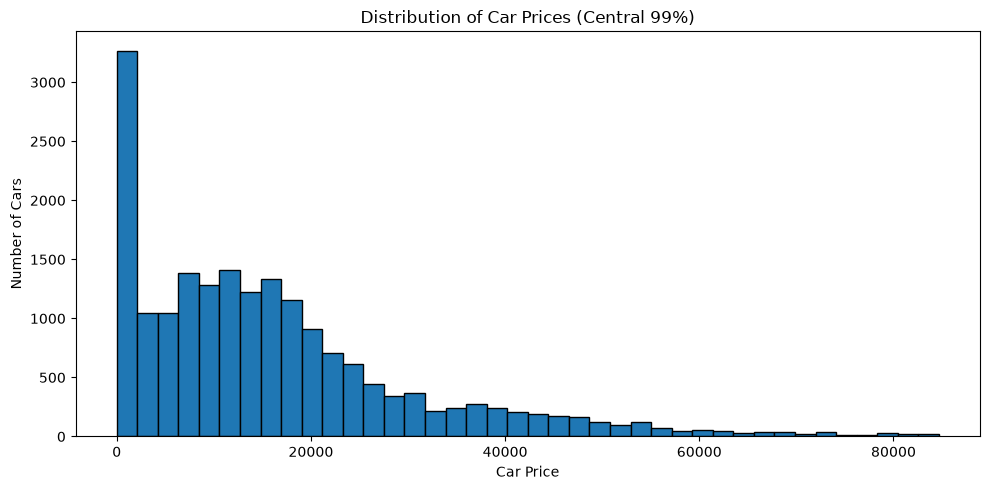

In [11]:
import matplotlib.pyplot as plt

# Keep positive prices for plotting
prices = df.loc[df["Price"] > 0, "Price"]

# Use the 99th percentile as the viewing limit
upper_limit = prices.quantile(0.99)
prices_to_plot = prices[prices <= upper_limit]

plt.figure(figsize=(10, 5))
plt.hist(prices_to_plot, bins=40, edgecolor="black")

plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Car Prices (Central 99%)")
plt.tight_layout()
plt.show()

 The car price distribution contains extreme values that require further investigation. These values should not be removed from the dataset without checking whether they are genuine or incorrect records.  


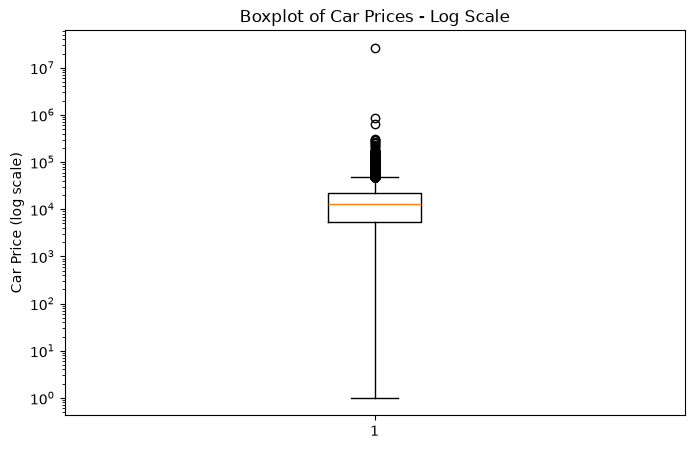

In [12]:

plt.figure(figsize=(8, 5))

plt.boxplot(df["Price"])

plt.yscale("log")
plt.ylabel("Car Price (log scale)")
plt.title("Boxplot of Car Prices - Log Scale")

plt.show()

observation:The boxplot helps visualize the spread and median of car prices.

Points beyond the whiskers indicate potential outliers.

Extremely high prices can make the central box appear compressed.

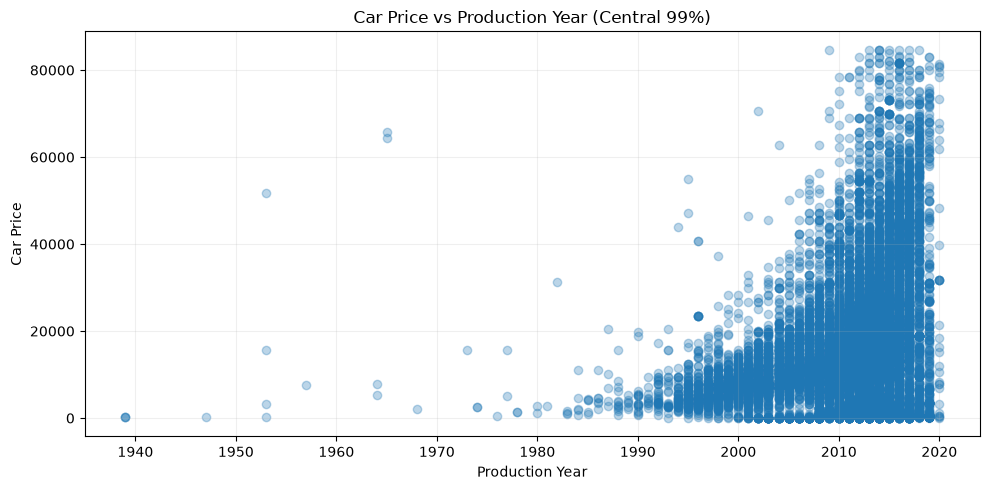

In [13]:

import matplotlib.pyplot as plt

# Limit prices for visualization only
upper_limit = df["Price"].quantile(0.99)
plot_df = df[df["Price"] <= upper_limit]

plt.figure(figsize=(10, 5))

plt.scatter(
    plot_df["Prod. year"],
    plot_df["Price"],
    alpha=0.3
)

plt.xlabel("Production Year")
plt.ylabel("Car Price")
plt.title("Car Price vs Production Year (Central 99%)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Observation:** The graph indicates a positive relationship between production year and car price. In general, newer cars tend to have higher prices. However, prices vary among cars from the same production year, so other features are also important for price prediction.

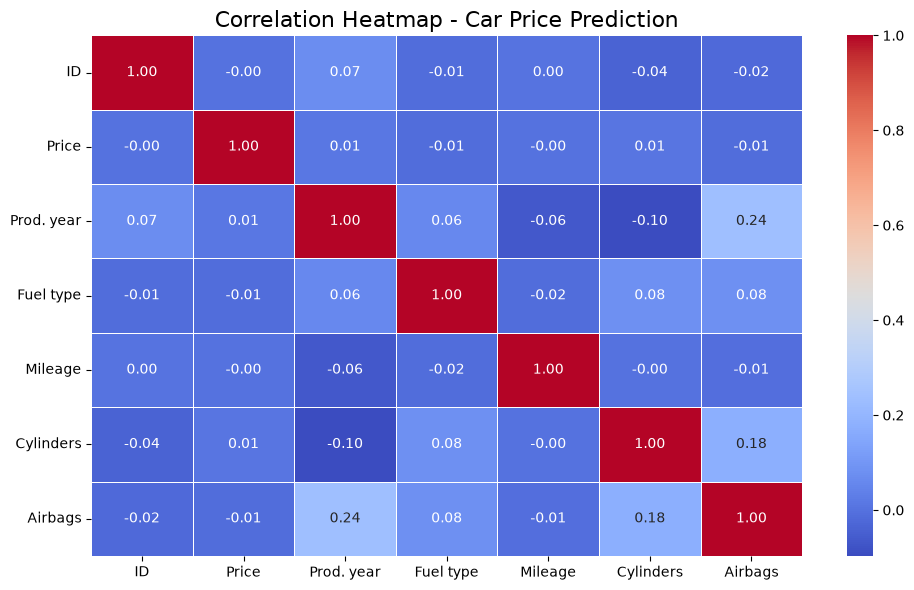

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Draw heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Car Price Prediction", fontsize=16)
plt.tight_layout()
plt.show()


In [46]:
price_correlation = numeric_df.corr()["Price"].sort_values(ascending=False)
print("Correlation of Variables with Car Price:")
display(price_correlation)

Correlation of Variables with Car Price:


Price         1.000000
Prod. year    0.012982
Cylinders     0.007518
ID           -0.000844
Mileage      -0.001758
Fuel type    -0.012419
Airbags      -0.012824
Name: Price, dtype: float64

**Step 3: Model Development**

•	Split dataset into train and test sets.

define x and y 

In [47]:
x = df.drop(columns=["Price", "ID", "Doors", "Engine volume", "Prod. year"])
y = np.log1p(df["Price"])      
display(x.head())
display(y.head())

,Levy,Manufacturer,Model,Category,Leather interior,Fuel type,Mileage,Cylinders,Gear box type,Drive wheels,Wheel,Color,Airbags,Engine,Turbo,Age
0,1399.0,LEXUS,RX 450,Jeep,Yes,2,186005.0,6.0,Automatic,4x4,Left wheel,Silver,12,3.5,0,10
1,1018.0,CHEVROLET,Equinox,Jeep,No,5,192000.0,6.0,Tiptronic,4x4,Left wheel,Black,8,3.0,0,9
2,NaN,HONDA,FIT,Hatchback,No,5,200000.0,4.0,Variator,Front,Right-hand drive,Black,2,1.3,0,14
3,862.0,FORD,Escape,Jeep,Yes,2,168966.0,4.0,Automatic,4x4,Left wheel,White,0,2.5,0,9
4,446.0,HONDA,FIT,Hatchback,Yes,5,91901.0,4.0,Automatic,Front,Left wheel,Silver,4,1.3,0,6


0    9.497697
1    9.718482
2    9.044050
3    8.190909
4    9.369649
Name: Price, dtype: float64

In [48]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)

In [49]:
print(xtrain.shape,xtest.shape)

(13231, 16) (3308, 16)


In [50]:
print(ytrain.shape,ytest.shape)

(13231,) (3308,)


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

# Numerical ani categorical columns olkha
numeric_columns = xtrain.select_dtypes(include="number").columns
categorical_columns = xtrain.select_dtypes(exclude="number").columns

# Numerical: missing -> median, mag scaling
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: missing -> most frequent, mag One-Hot
# min_frequency=30: 30 peksha kami gadya astil tya categories ekatra (overfitting talnyasathi)
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

# Linear Regression model
model1 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression Model Created Successfully!")

Linear Regression Model Created Successfully!


In [52]:
# Train the Linear Regression model
model1.fit(xtrain, ytrain)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [53]:
# Test data var kimmat predict kara (log madhun parat original price madhe)
y_pred_log = model1.predict(xtest)
y_pred = np.expm1(y_pred_log)
ytest_actual = np.expm1(ytest)

results = pd.DataFrame({
    "Actual Price": np.asarray(ytest_actual).reshape(-1),
    "Predicted Price": np.asarray(y_pred).reshape(-1).round(0)
})

print("Actual vs Predicted Car Prices:")
display(results.head(10))

Actual vs Predicted Car Prices:


,Actual Price,Predicted Price
0,7527.0,7271.0
1,41867.0,19065.0
2,17876.0,19900.0
3,22580.0,8933.0
4,26814.0,18205.0
5,706.0,8252.0
6,20385.0,29309.0
7,19757.0,14390.0
8,10976.0,8830.0
9,7840.0,8837.0


***step 4 :Module Evalution***

In [54]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2 = r2_score(ytest_actual, y_pred)
mae = mean_absolute_error(ytest_actual, y_pred)
mse = mean_squared_error(ytest_actual, y_pred)
rmse = np.sqrt(mse)

print("Model Evaluation Results")
print("------------------------")
print("R² Score:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

# Overfitting tapasa: training R² la test R² shi tulna kara
train_pred = np.expm1(model1.predict(xtrain))
print("\nTrain R²:", r2_score(np.expm1(ytrain), train_pred))

Model Evaluation Results
------------------------
R² Score: 0.32001777222357497
Mean Absolute Error (MAE): 8132.316727723018
Mean Squared Error (MSE): 155729904.91591215
Root Mean Squared Error (RMSE): 12479.178855834713

Train R²: 0.34320931070949035


# Car Price Prediction Using Machine Learning

##  Problem Statement & Dataset Description
- **Problem:** Predict car prices using machine learning.
- **Objective:** Understand how car features relate to selling price.
- **Target Variable:** Price
- **Features:** Manufacturer, production year, mileage, fuel type, engine volume, airbags and other car attributes.
- **Dataset:** Contains information about cars and their features.

## Data Preprocessing
- Removed duplicate records.
- Handled missing values using imputation.
- Converted numerical columns into appropriate data types.
- Applied One-Hot Encoding to categorical variables.
- Split the dataset into 80% training data and 20% testing data.

##  Key Insights from EDA
- Used histograms to understand data distributions.
- Used boxplots to inspect potential outliers.
- Analyzed the relationship between Price and Production Year using a scatter plot.
- Used a correlation heatmap to explore relationships between numerical features.
- Observed that the Price distribution is highly right-skewed.

## Linear Regression Model
- Linear Regression is a supervised machine learning algorithm.
- It predicts a numerical target using input features.
- Input: Car features such as manufacturer, mileage and production year.
- Output: Predicted car price.
- The model was trained on the training dataset and evaluated on unseen test data.

##  Model Evaluation Results
- R² Score: 0.32001777222357497
- Mean Absolute Error (MAE): 8132.316727723018
- Mean Squared Error (MSE): 155729904.91591215
- Root Mean Squared Error (RMSE): 12479.178855834713


**Interpretation:**
- MAE and RMSE indicate substantial prediction errors.
- The negative R² score means the model performs worse than predicting the mean car price on the test dataset.
- The current model has weak predictive performance.

##  Conclusion & Future Improvements
- Completed data preprocessing, EDA and Linear Regression modelling.
- The current model does not predict car prices reliably.
- Investigate extreme price values and improve feature selection.
- Evaluate alternative regression algorithms.
- Tune and compare models using the same test dataset.

